In [1]:
import os
import random
import shutil
from collections import Counter, defaultdict
from math import ceil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from sklearn.metrics import confusion_matrix
from torch.utils.data import DataLoader, TensorDataset
from torchvision.datasets import ImageFolder

sns.set_theme()

random.seed(0)
np.random.seed(0)
torch.manual_seed(0)

(current_device := torch.device("cuda" if torch.cuda.is_available() else "cpu"))

device(type='cuda')

# Подготовка тестовых данных

In [2]:
# Среднее и стандартное отклонение по трём цветовым каналам, посчитанные на ImageNet
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]
image_size = 224
batch_size = 32

base_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

photos_path = "./test/photos"
photos_dataset = ImageFolder(photos_path, transform=base_transform)
photos_loader = DataLoader(photos_dataset, batch_size=batch_size, shuffle=False)

class_names = photos_dataset.classes
n_classes = len(class_names)

photos_targets = photos_dataset.targets
photos_counts = {class_names[target]: cnt for target, cnt in Counter(photos_targets).items()}

photos_indices = defaultdict(list)
for image_index, target in enumerate(photos_targets):
    photos_indices[class_names[target]].append(image_index)

print("Количество новых изображений каждого класса:")
for class_name, cnt in photos_counts.items():
    print(f"'{class_name}': {cnt}")

Количество новых изображений каждого класса:
'dew': 12
'fogsmog': 12
'frost': 12
'glaze': 12
'hail': 12
'lightning': 12
'rain': 12
'rainbow': 12
'rime': 12
'sandstorm': 12
'snow': 12


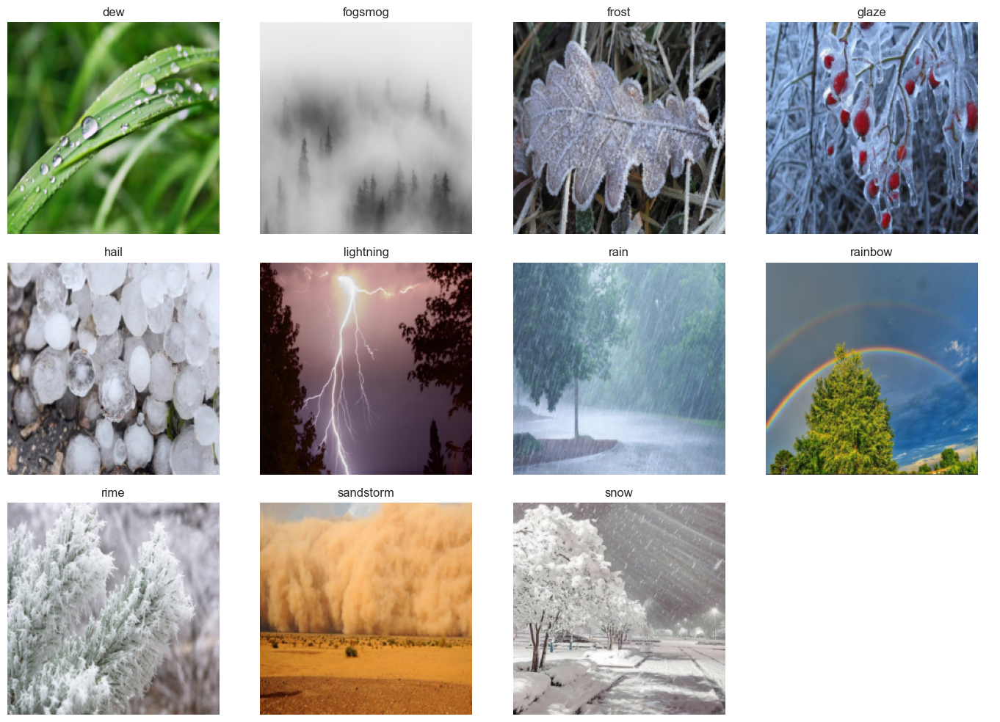

In [3]:
def get_image_array_from_tensor(image_tensor):
    mean_tensor = torch.tensor(mean).view(3, 1, 1)
    std_tensor = torch.tensor(std).view(3, 1, 1)

    image_tensor = image_tensor * std_tensor + mean_tensor
    image_tensor = image_tensor.clamp(0, 1)
    image_array = image_tensor.permute(1, 2, 0).detach().cpu().numpy()

    return image_array


def plot_image_samples(dataset, indices_dict):
    _, axes = plt.subplots(nrows=3, ncols=4, figsize=(14, 10))
    axes = axes.flatten()

    for i, class_name in enumerate(class_names):
        axes[i].imshow(get_image_array_from_tensor(dataset[indices_dict[class_name][0]][0]))
        axes[i].axis("off")
        axes[i].set_title(class_name)

    axes[-1].axis("off")

    plt.tight_layout()


plot_image_samples(dataset=photos_dataset, indices_dict=photos_indices)

In [4]:
data_path = "./data/weather"
aug_path = "./test/aug"

n_images_per_class = 12

if not os.listdir(os.path.join(aug_path, class_names[0])):
    for class_name in class_names:
        source_dir = os.path.join(data_path, class_name)
        target_dir = os.path.join(aug_path, class_name)

        image_paths = [image_path for image_path in os.listdir(source_dir)]

        for image_path in random.sample(image_paths, k=n_images_per_class):
            shutil.copy(
                os.path.join(source_dir, image_path),
                os.path.join(target_dir, image_path)
            )

aug_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=30),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1),
    transforms.RandomResizedCrop(size=image_size, scale=(0.7, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

aug_dataset_path = "./test/weather_aug.pt"

if not os.path.exists(aug_dataset_path):
    raw_aug_dataset = ImageFolder(aug_path, transform=aug_transform)

    aug_tensors_list = []
    aug_targets_list = []

    for image_index in range(len(raw_aug_dataset)):
        image_tensor, target = raw_aug_dataset[image_index]
        aug_tensors_list.append(image_tensor)
        aug_targets_list.append(target)
        
    aug_images_tensor = torch.stack(aug_tensors_list)
    aug_targets_tensor = torch.tensor(aug_targets_list)

    torch.save((aug_images_tensor, aug_targets_tensor), aug_dataset_path)

else:
    aug_images_tensor, aug_targets_tensor = torch.load(aug_dataset_path)

aug_dataset = TensorDataset(aug_images_tensor, aug_targets_tensor)
aug_loader = DataLoader(aug_dataset, batch_size=batch_size, shuffle=False)

aug_targets = aug_targets_tensor.tolist()
aug_counts = {class_names[target]: cnt for target, cnt in Counter(aug_targets).items()}

aug_indices = defaultdict(list)
for image_index, target in enumerate(aug_targets):
    aug_indices[class_names[target]].append(image_index)

print("Количество аугментированных изображений каждого класса:")
for class_name, cnt in aug_counts.items():
    print(f"'{class_name}': {cnt}")

Количество аугментированных изображений каждого класса:
'dew': 12
'fogsmog': 12
'frost': 12
'glaze': 12
'hail': 12
'lightning': 12
'rain': 12
'rainbow': 12
'rime': 12
'sandstorm': 12
'snow': 12


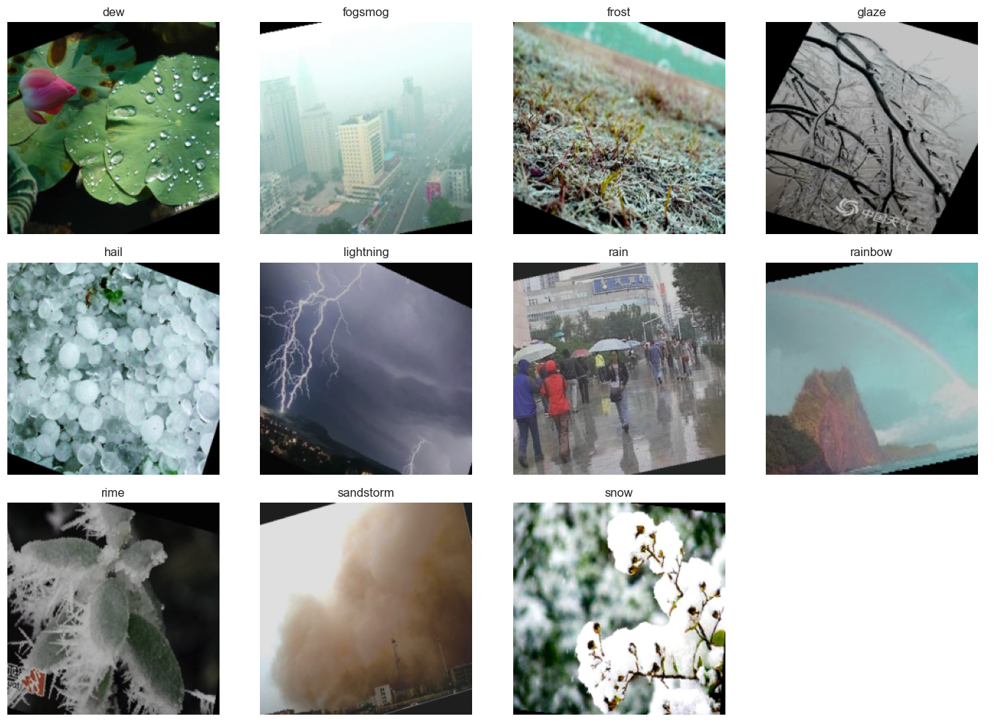

In [5]:
plot_image_samples(dataset=aug_dataset, indices_dict=aug_indices)

# Инициализация моделей

In [6]:
class WeatherMLP(nn.Module):
    def __init__(self, n_classes):
        super().__init__()

        # (batch, 3, 224, 224) -> (batch, 3, 16, 16)
        self.input_pool = nn.AdaptiveAvgPool2d((16, 16))

        self.classifier = nn.Sequential(
            nn.Flatten(),  # (batch, 3, 16, 16) -> (batch, 768)
            nn.Linear(3 * 16 * 16, 512),  # (batch, 768) -> (batch, 512)
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, 256),  # (batch, 512) -> (batch, 256)
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, n_classes)  # (batch, 256) -> (batch, n_classes)
        )

    def forward(self, x):
        x = self.input_pool(x)
        return self.classifier(x)


class WeatherCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()

        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),  # (batch, 3, 224, 224) -> (batch, 32, 224, 224)
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),  # (batch, 32, 224, 224) -> (batch, 32, 224, 224)
            nn.ReLU(),
            nn.MaxPool2d(2),  # (batch, 32, 224, 224) -> (batch, 32, 112, 112)
            nn.Dropout2d(0.2),
        )

        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),  # (batch, 32, 112, 112) -> (batch, 64, 112, 112)
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),  # (batch, 64, 112, 112) -> (batch, 64, 112, 112)
            nn.ReLU(),
            nn.MaxPool2d(2),  # (batch, 64, 112, 112) -> (batch, 64, 56, 56)
            nn.Dropout2d(0.3),
        )

        self.conv_block_3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),  # (batch, 64, 56, 56) -> (batch, 128, 56, 56)
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),  # (batch, 128, 56, 56) -> (batch, 128, 56, 56)
            nn.ReLU(),
            nn.MaxPool2d(2),  # (batch, 128, 56, 56) -> (batch, 128, 28, 28)
            nn.Dropout2d(0.4),
        )

        self.conv_block_4 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),  # (batch, 128, 28, 28) -> (batch, 256, 28, 28)
            nn.ReLU(),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),  # (batch, 256, 28, 28) -> (batch, 256, 28, 28)
            nn.ReLU(),
            nn.MaxPool2d(2),  # (batch, 256, 28, 28) -> (batch, 256, 14, 14)
            nn.Dropout2d(0.4),
        )

        # (batch, 256, 14, 14) -> (batch, 256, 4, 4)
        self.global_pool = nn.AdaptiveAvgPool2d((4, 4))

        self.classifier = nn.Sequential(
            nn.Flatten(),  # (batch, 256, 4, 4) -> (batch, 4096)
            nn.Linear(256 * 4 * 4, 256),  # (batch, 4096) -> (batch, 256)
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, n_classes),  # (batch, 256) -> (batch, n_classes)
        )

    def forward(self, x):
        x = self.conv_block_1(x)
        x = self.conv_block_2(x)
        x = self.conv_block_3(x)
        x = self.conv_block_4(x)
        x = self.global_pool(x)
        return self.classifier(x)


resnet18 = models.resnet18()
resnet18.fc = nn.Linear(resnet18.fc.in_features, n_classes)

mobilenet_v3_large = models.mobilenet_v3_large()
mobilenet_v3_large.classifier[3] = nn.Linear(mobilenet_v3_large.classifier[3].in_features, n_classes)

efficientnet_b0 = models.efficientnet_b0()
efficientnet_b0.classifier[1] = nn.Linear(efficientnet_b0.classifier[1].in_features, n_classes)

models_dict = {
    "WeatherMLP": WeatherMLP(n_classes=n_classes),
    "WeatherCNN": WeatherCNN(n_classes=n_classes),
    "ResNet18": resnet18,
    "MobileNetV3-Large": mobilenet_v3_large,
    "EfficientNet-B0": efficientnet_b0,
}

models_short = {
    "WeatherMLP": "MLP",
    "WeatherCNN": "CNN",
    "ResNet18": "ResNet",
    "MobileNetV3-Large": "MobNet",
    "EfficientNet-B0": "EffNet",
}

for model_name, model in models_dict.items():
    model = model.to(current_device)
    model.load_state_dict(
        torch.load(f"./models/{model_name}.pt", map_location=current_device)
    )
    params = sum(p.numel() for p in model.parameters())
    print(f"{model_name}: {params} параметров")

WeatherMLP: 527883 параметров
WeatherCNN: 2223915 параметров
ResNet18: 11182155 параметров
MobileNetV3-Large: 4216123 параметров
EfficientNet-B0: 4021639 параметров


# Тестирование моделей на новых изображениях

In [7]:
def evaluate_predict(model, loader, device):
    model.eval()

    correct, total = 0, 0
    all_preds, all_probs = [], []

    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            probs = torch.softmax(outputs, dim=1)

            correct += (preds == targets).sum().item()
            total += targets.size(0)

            all_preds.append(preds.cpu())
            all_probs.append(probs.cpu())
    
    return correct / total, torch.cat(all_preds).numpy(), torch.cat(all_probs).numpy()


def get_models_preds(models_dict, targets, loader):
    all_preds = []

    for model_name, model in models_dict.items():
        acc, preds, probs = evaluate_predict(model, loader, current_device)
        cm = confusion_matrix(targets, preds)

        all_preds.append({
            "model": model_name,
            "acc": acc,
            "preds": preds,
            "probs": probs,
            "cm": cm,
        })
    
    return all_preds


def get_models_results(all_preds, targets, dataset_size):
    results = []

    for preds in all_preds:
        correct = (preds["preds"] == targets).sum().item()

        results.append({
            "Модель": preds["model"],
            "Точность": f"{preds["acc"]:.4f}",
            "Ошибок": dataset_size - correct,
        })
    
    return results


photos_preds = get_models_preds(models_dict, targets=photos_targets, loader=photos_loader)
photos_results = get_models_results(photos_preds, targets=photos_targets, dataset_size=len(photos_dataset))
pd.DataFrame(photos_results).style.hide(axis="index")

Модель,Точность,Ошибок
WeatherMLP,0.5227,63
WeatherCNN,0.6970,40
ResNet18,0.8712,17
MobileNetV3-Large,0.8636,18
EfficientNet-B0,0.9015,13


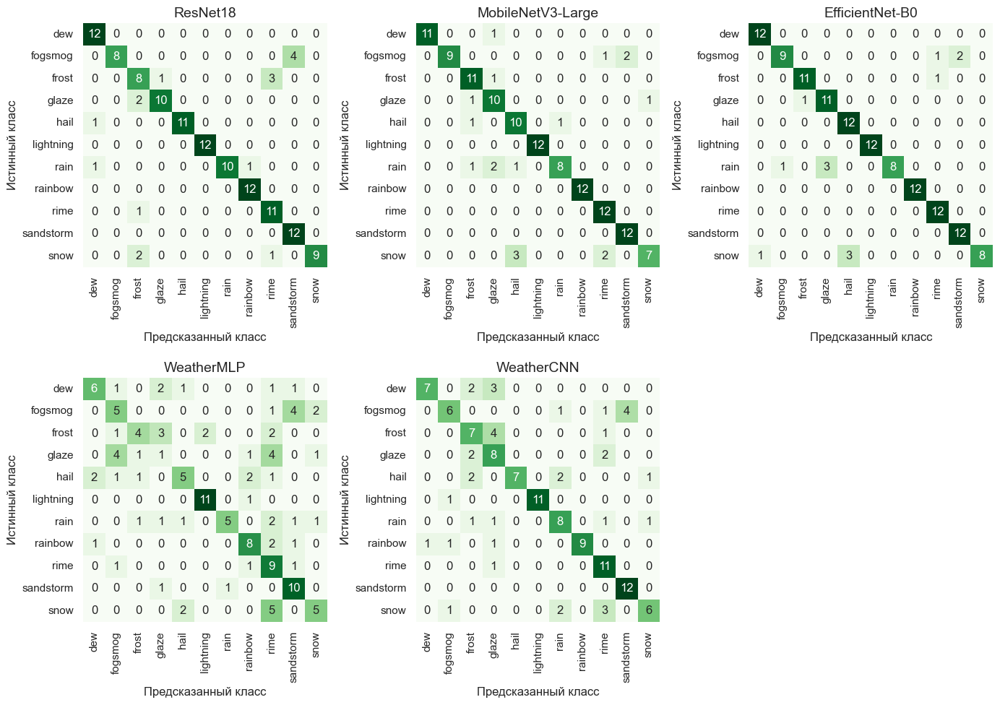

In [8]:
def plot_models_confusion_matrices(all_preds):
    _, axes = plt.subplots(nrows=2, ncols=3, figsize=(14, 10))
    axes = axes.flatten()

    for i, preds in enumerate(all_preds[2:] + all_preds[:2]):
        sns.heatmap(
            preds["cm"], cmap="Greens", annot=True, fmt="d", cbar=False, square=True, ax=axes[i]
        ).set(
            xlabel="Предсказанный класс", ylabel="Истинный класс",
            xticklabels=class_names, yticklabels=class_names
        )
        axes[i].set_title(preds["model"], fontsize=14)
        axes[i].tick_params(axis="x", rotation=90)
        axes[i].tick_params(axis="y", rotation=0)

    axes[-1].axis("off")

    plt.tight_layout()


plot_models_confusion_matrices(photos_preds)

# Анализ ошибок на новых изображениях

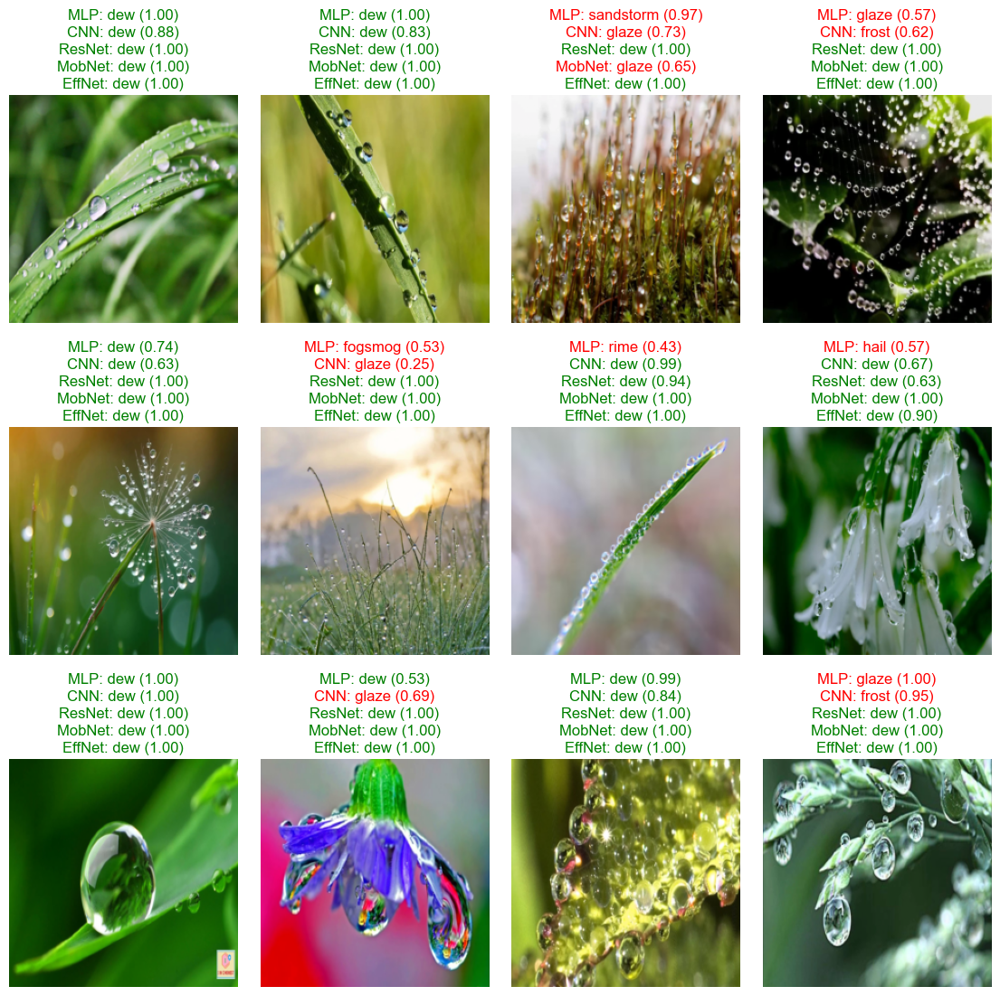

In [9]:
def plot_preds(class_name, dataset, indices_dict, all_preds):
    n_models = len(all_preds)

    image_indices = indices_dict[class_name]
    n_images = len(image_indices)

    n_cols = 4
    n_rows = ceil(n_images / n_cols)

    _, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(14, n_rows * 4.5))
    axes = axes.flatten()

    for i, image_index in enumerate(image_indices):
        ax = axes[i]

        ax.imshow(get_image_array_from_tensor(dataset[image_index][0]))
        ax.axis("off")

        model_names = [models_short[preds["model"]] for preds in all_preds]
        image_preds = [preds["preds"][image_index] for preds in all_preds]
        image_probs = [preds["probs"][image_index][image_preds[j]] for j, preds in enumerate(all_preds)]

        y_step = 0.075
        y_start = 1.02 + y_step * (n_models - 1)
        for k, model_name, pred, prob in zip(range(n_models), model_names, image_preds, image_probs):
            color = "green" if class_names[pred] == class_name else "red"
            line = f"{model_name}: {class_names[pred]} ({prob:.2f})"
            ax.text(
                0.5, y_start - k * y_step, line, transform=ax.transAxes,
                ha="center", va="bottom", color=color
            )

    for i in range(n_images, len(axes)):
        axes[i].axis("off")

    plt.subplots_adjust(wspace=0.1, hspace=0.2)


plot_preds("dew", dataset=photos_dataset, indices_dict=photos_indices, all_preds=photos_preds)

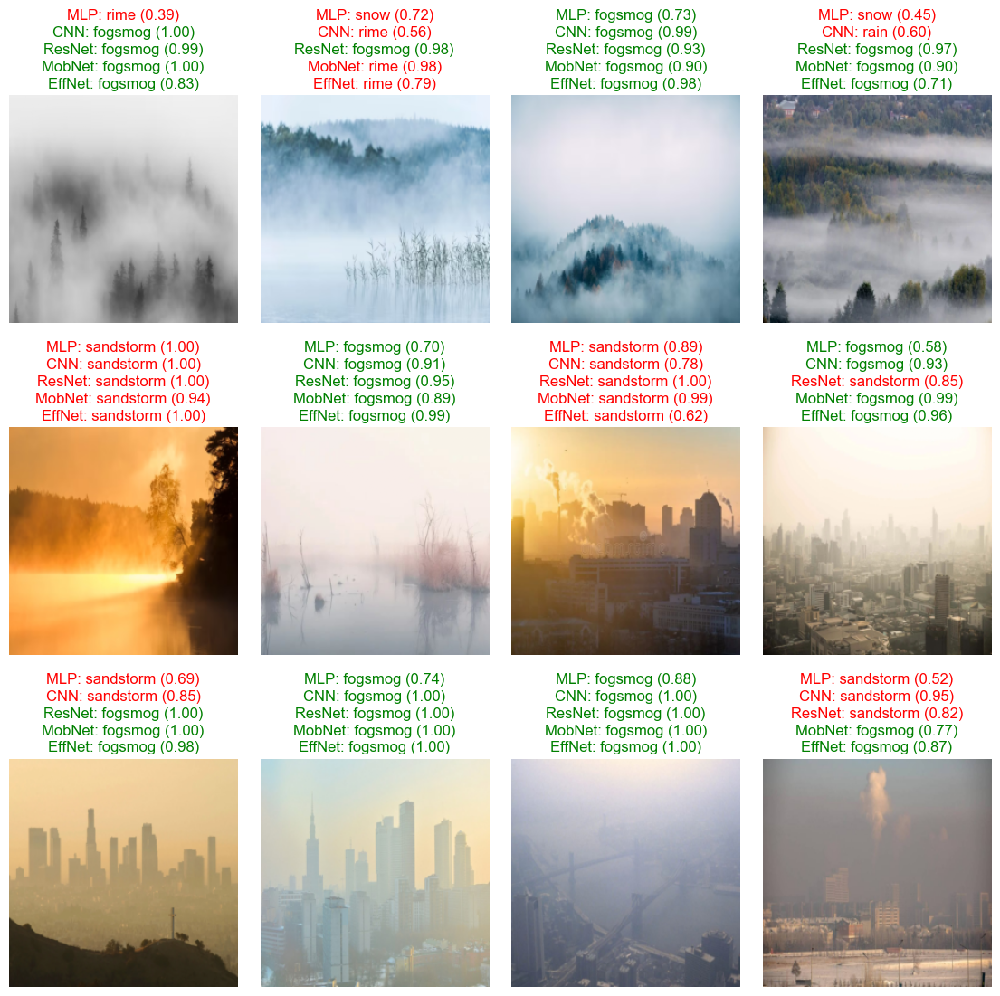

In [10]:
plot_preds("fogsmog", dataset=photos_dataset, indices_dict=photos_indices, all_preds=photos_preds)

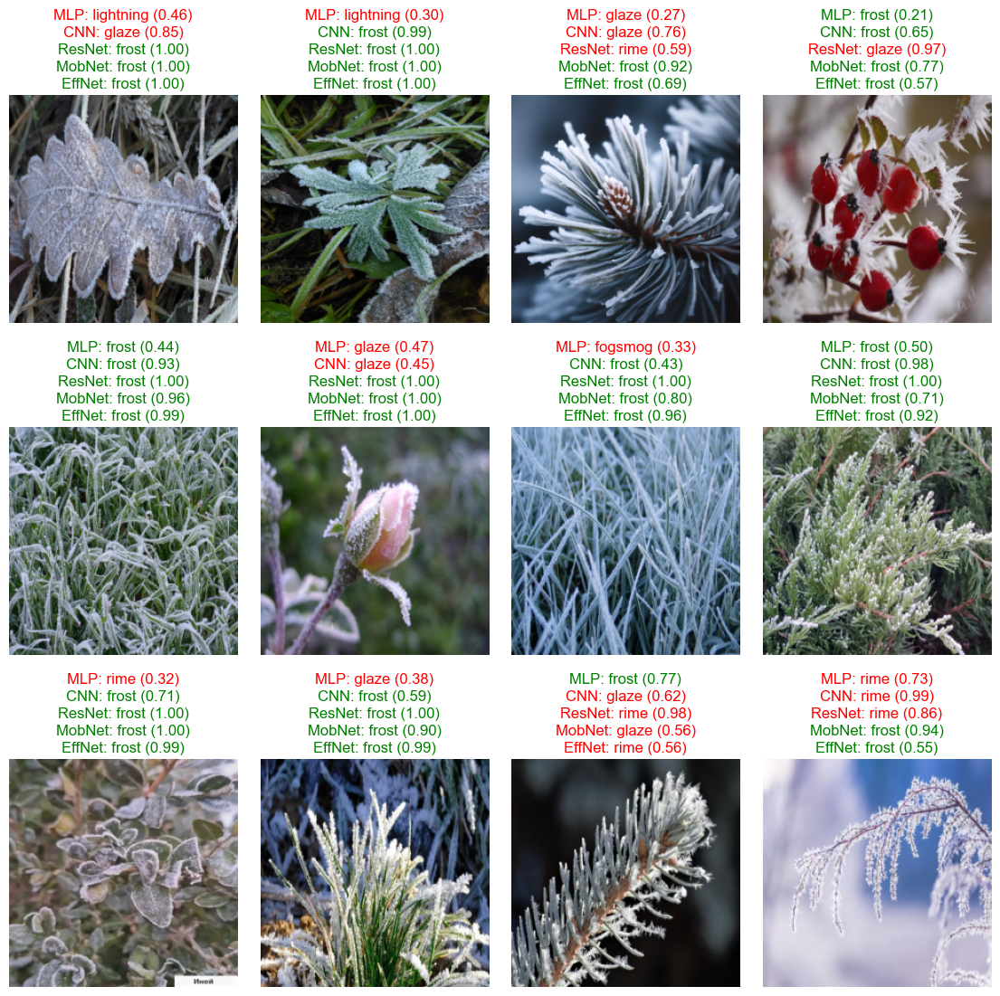

In [11]:
plot_preds("frost", dataset=photos_dataset, indices_dict=photos_indices, all_preds=photos_preds)

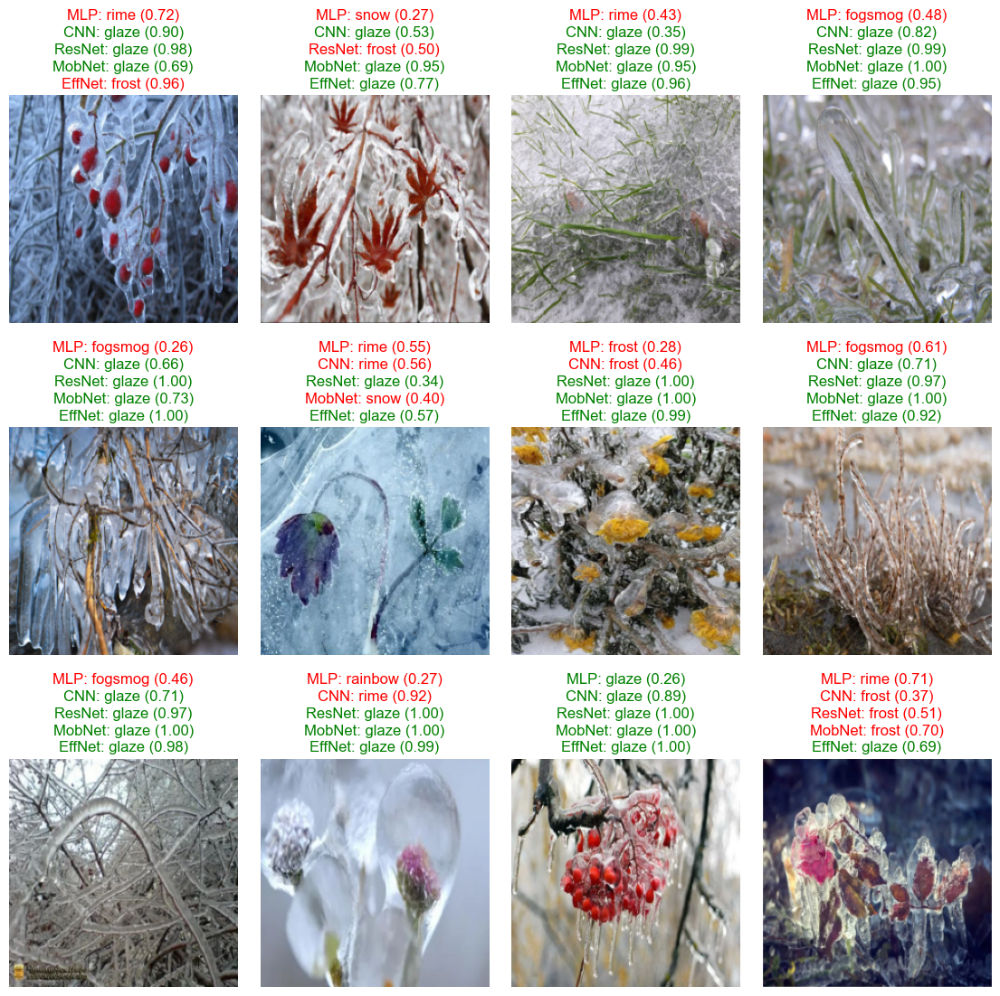

In [12]:
plot_preds("glaze", dataset=photos_dataset, indices_dict=photos_indices, all_preds=photos_preds)

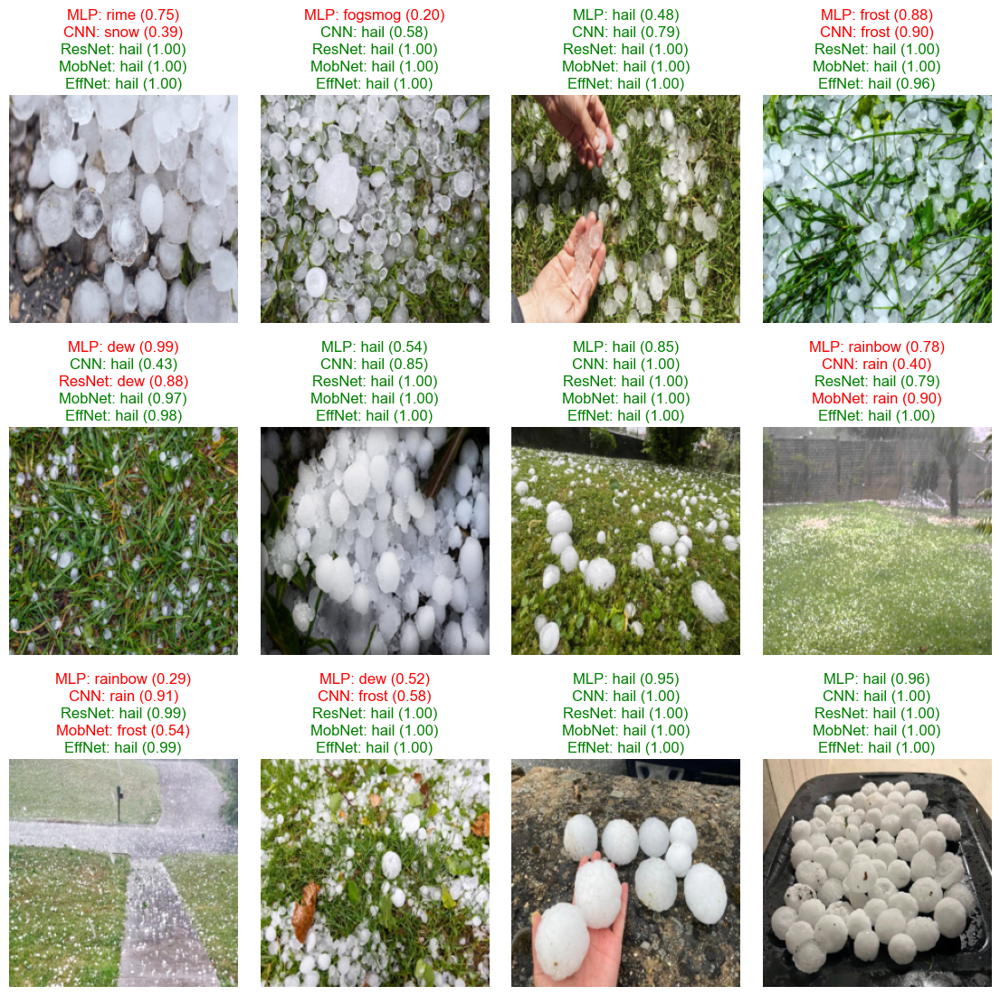

In [13]:
plot_preds("hail", dataset=photos_dataset, indices_dict=photos_indices, all_preds=photos_preds)

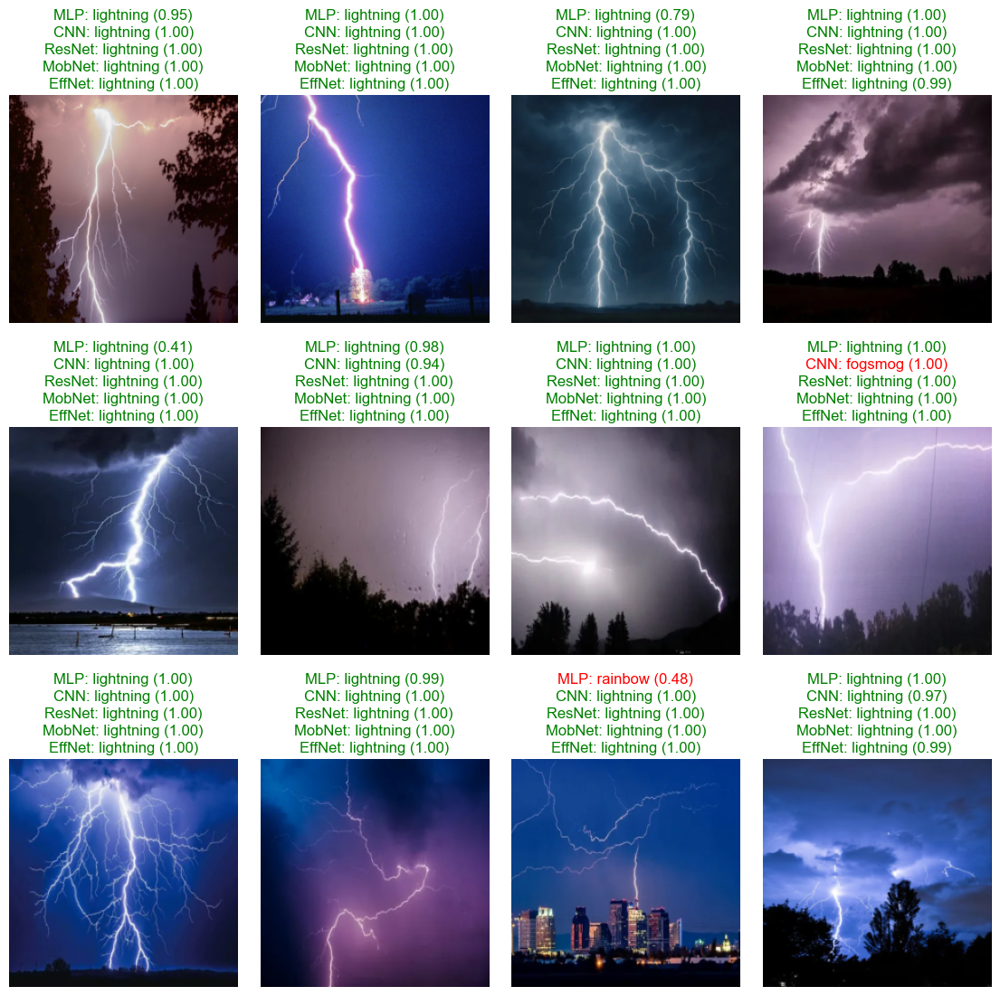

In [14]:
plot_preds("lightning", dataset=photos_dataset, indices_dict=photos_indices, all_preds=photos_preds)

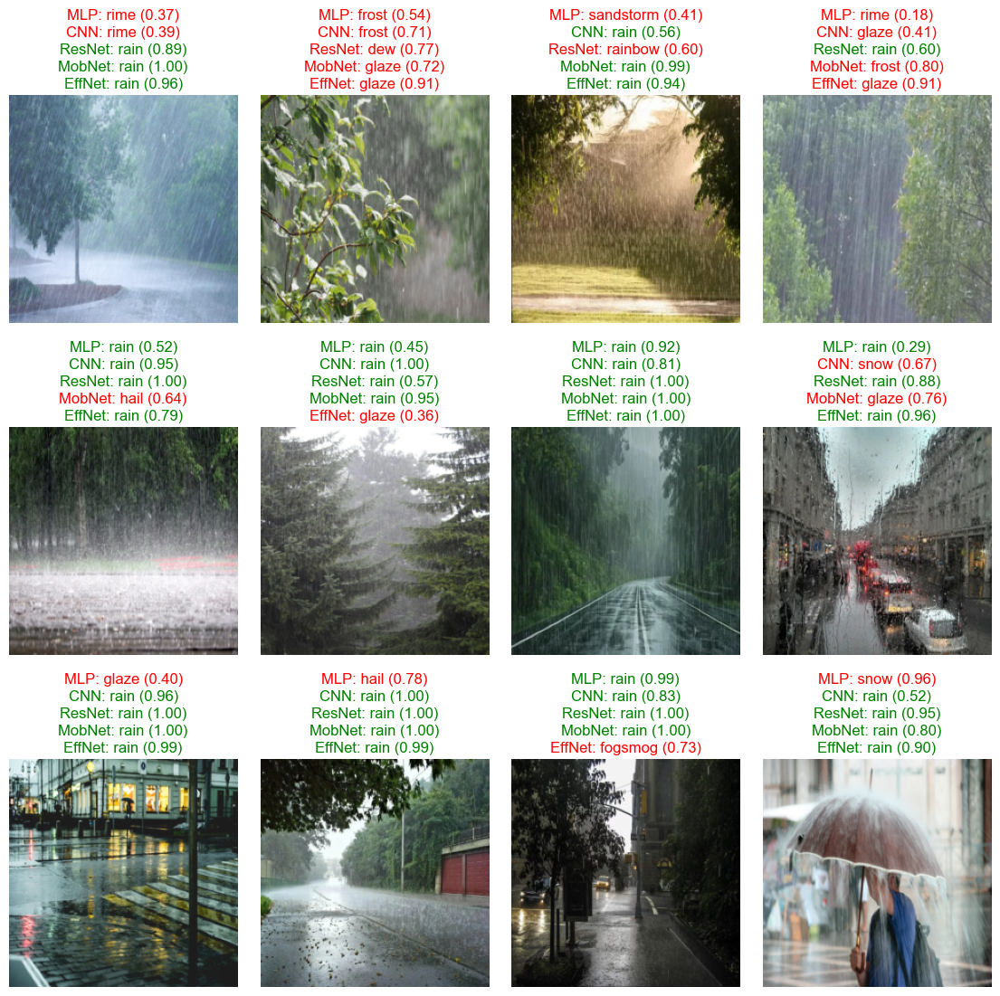

In [15]:
plot_preds("rain", dataset=photos_dataset, indices_dict=photos_indices, all_preds=photos_preds)

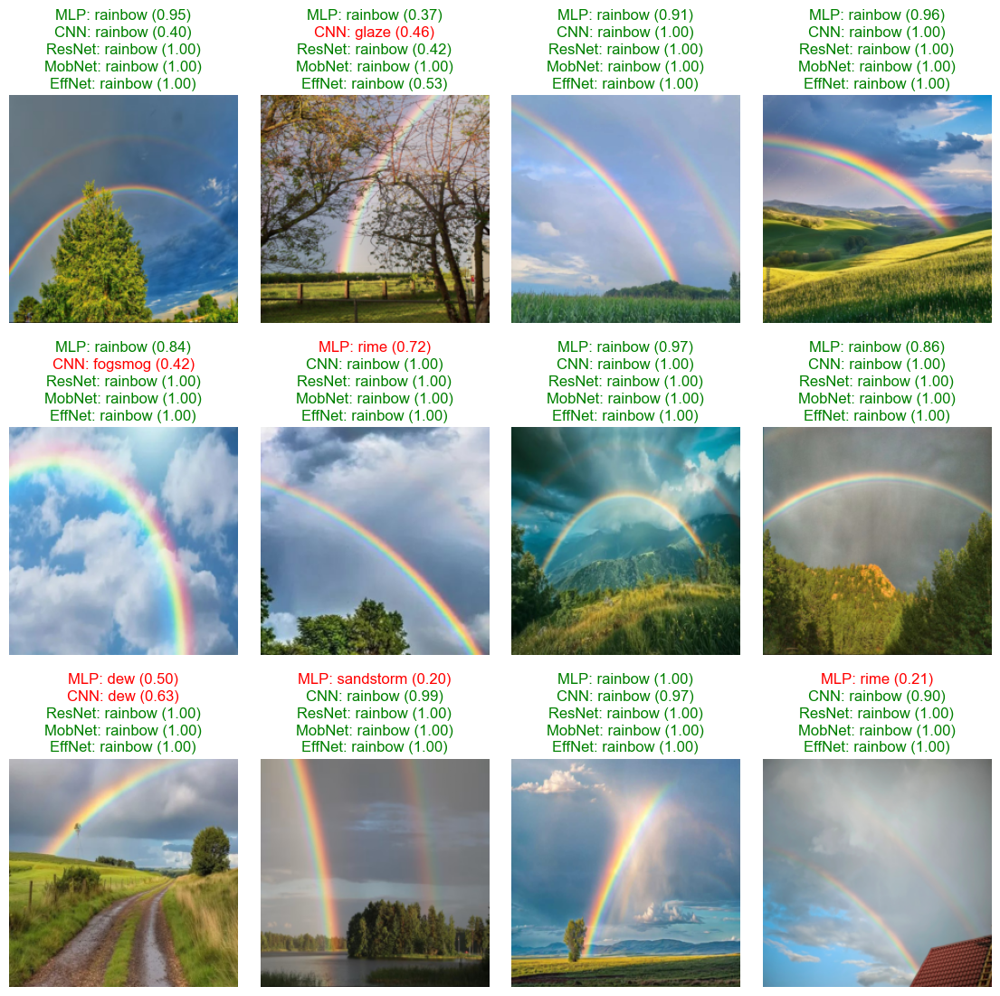

In [16]:
plot_preds("rainbow", dataset=photos_dataset, indices_dict=photos_indices, all_preds=photos_preds)

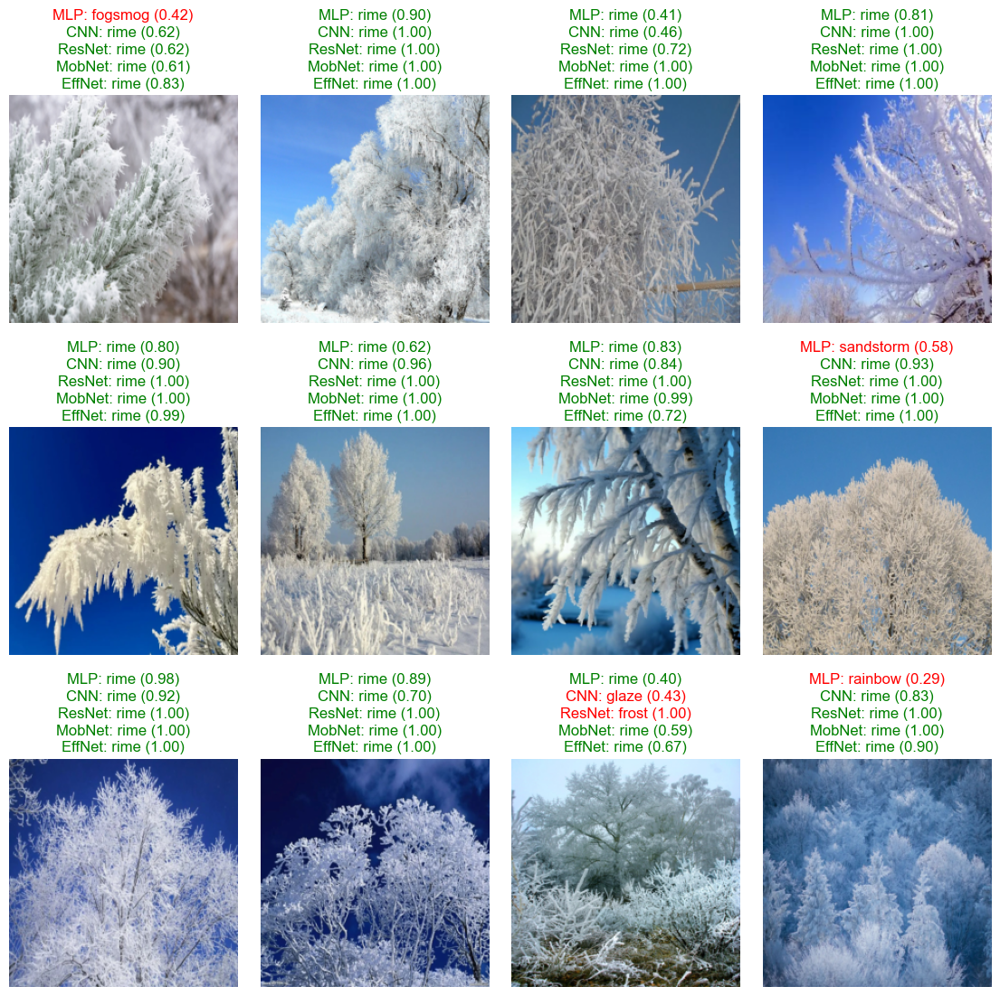

In [17]:
plot_preds("rime", dataset=photos_dataset, indices_dict=photos_indices, all_preds=photos_preds)

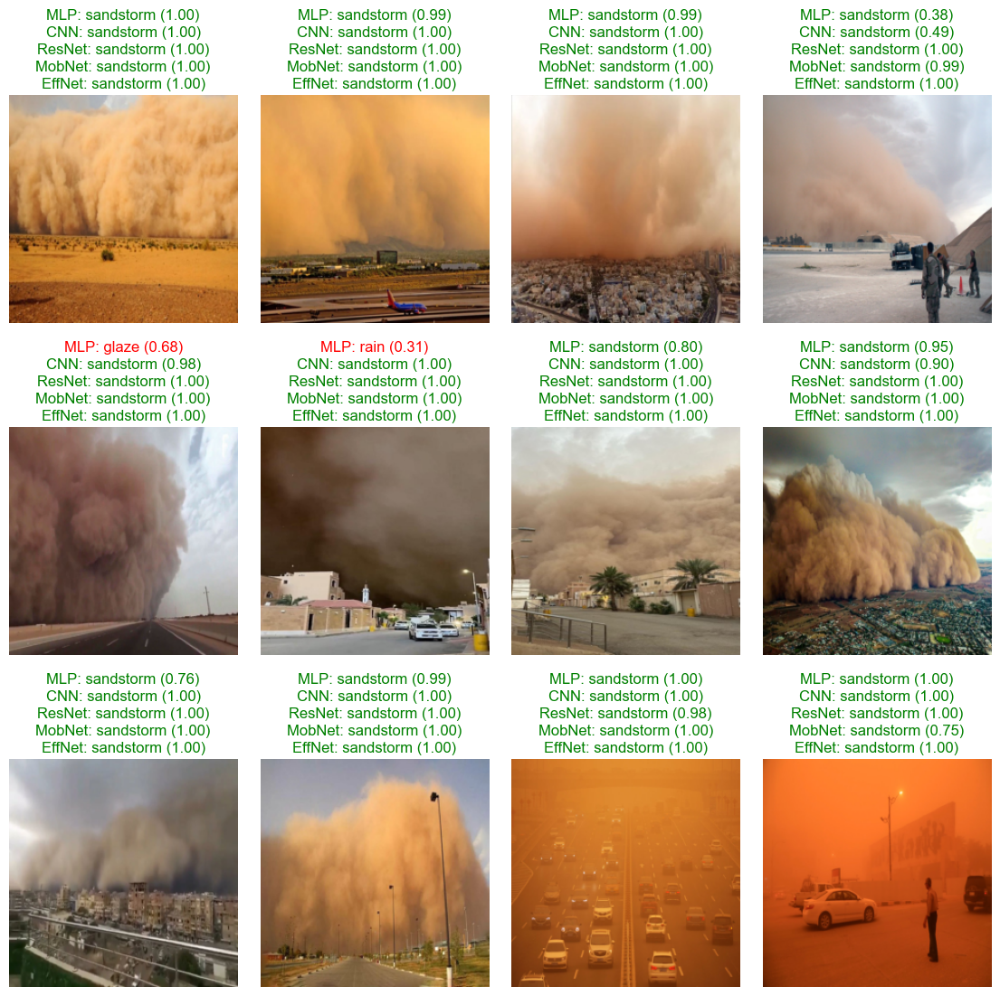

In [18]:
plot_preds("sandstorm", dataset=photos_dataset, indices_dict=photos_indices, all_preds=photos_preds)

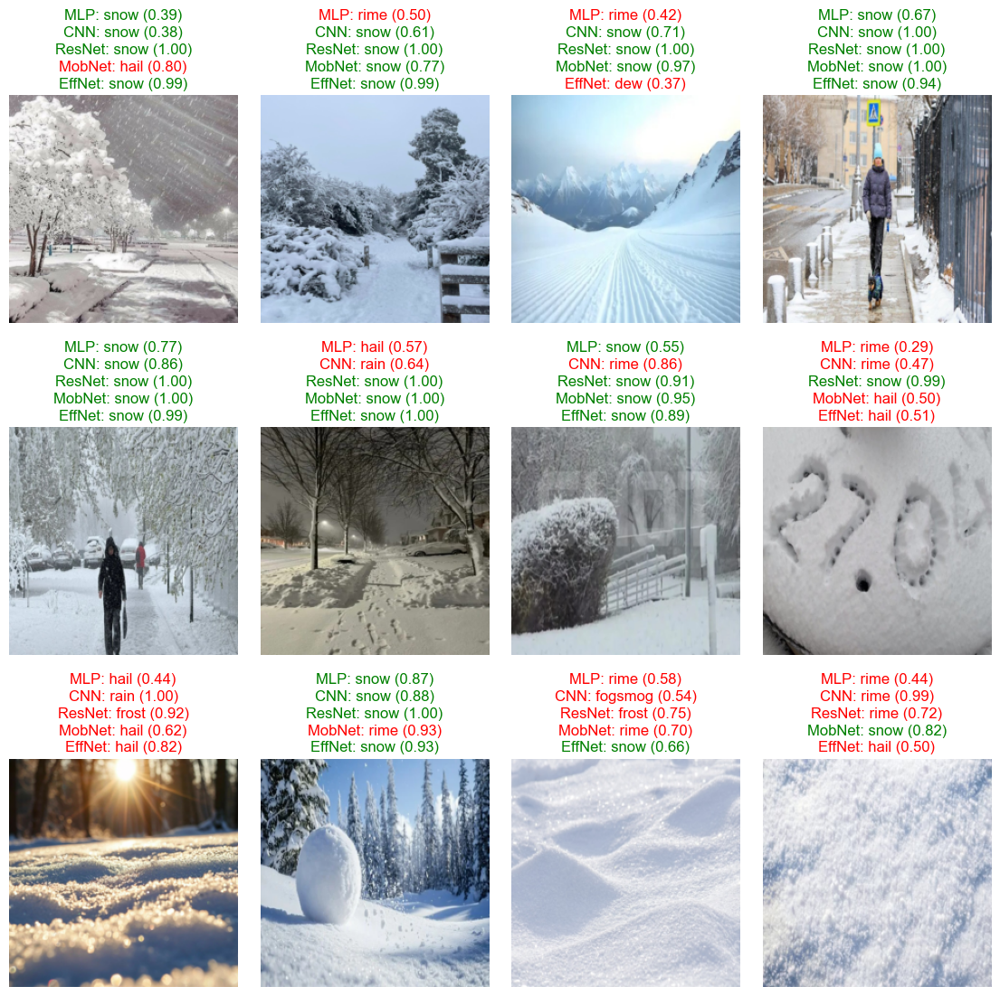

In [19]:
plot_preds("snow", dataset=photos_dataset, indices_dict=photos_indices, all_preds=photos_preds)

# Тестирование моделей на аугментированных изображениях

In [20]:
aug_preds = get_models_preds(models_dict, targets=aug_targets, loader=aug_loader)
aug_results = get_models_results(aug_preds, targets=aug_targets, dataset_size=len(aug_dataset))
pd.DataFrame(aug_results).style.hide(axis="index")

Модель,Точность,Ошибок
WeatherMLP,0.4091,78
WeatherCNN,0.5303,62
ResNet18,0.8485,20
MobileNetV3-Large,0.8636,18
EfficientNet-B0,0.9091,12


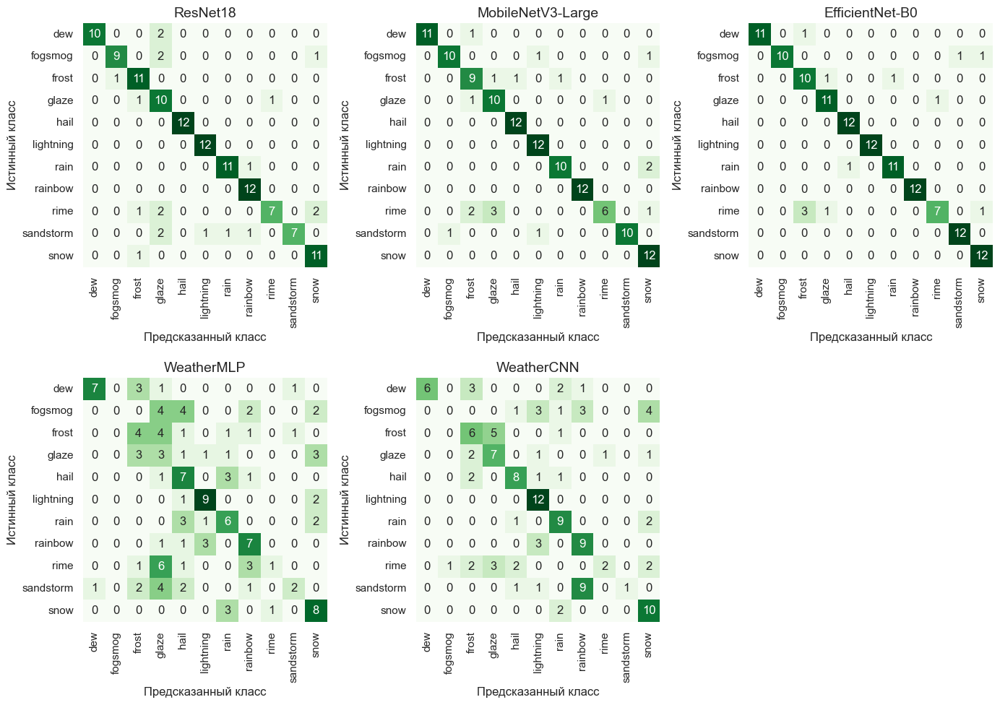

In [21]:
plot_models_confusion_matrices(aug_preds)

# Анализ ошибок на аугментированных изображениях

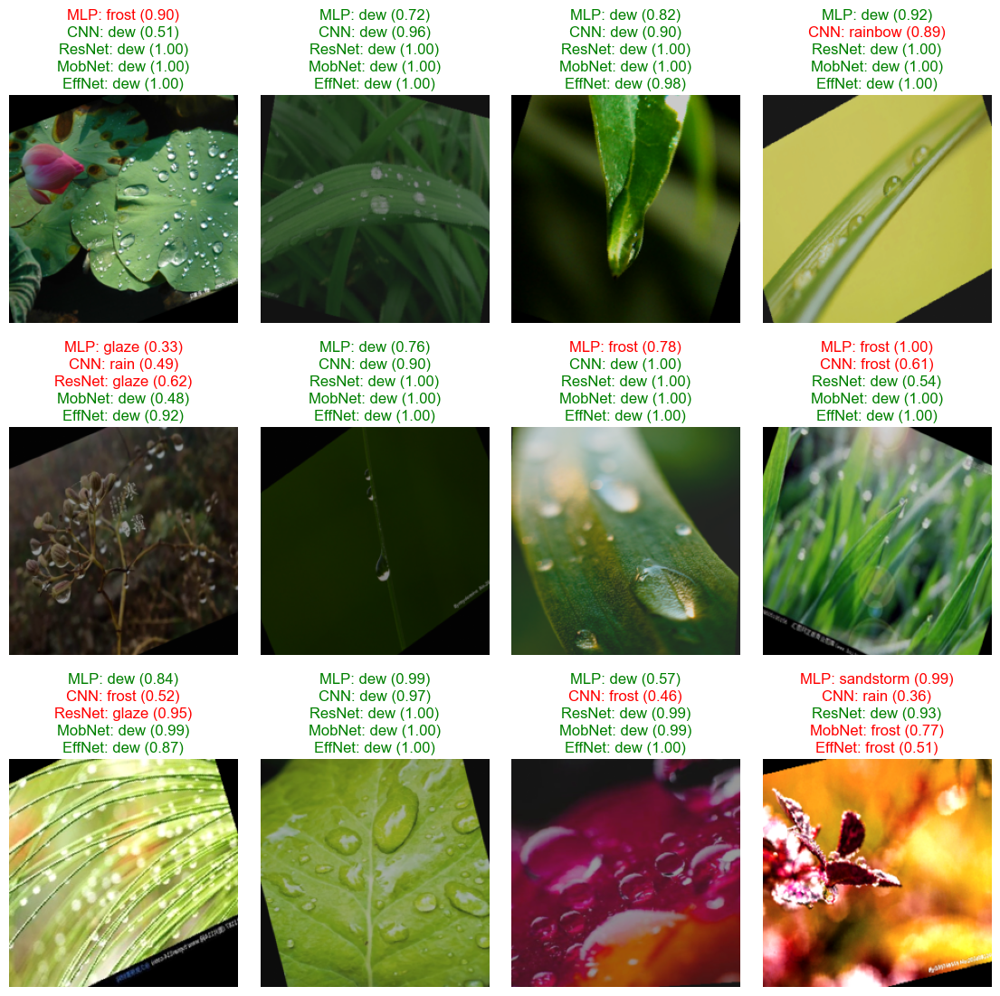

In [22]:
plot_preds("dew", dataset=aug_dataset, indices_dict=aug_indices, all_preds=aug_preds)

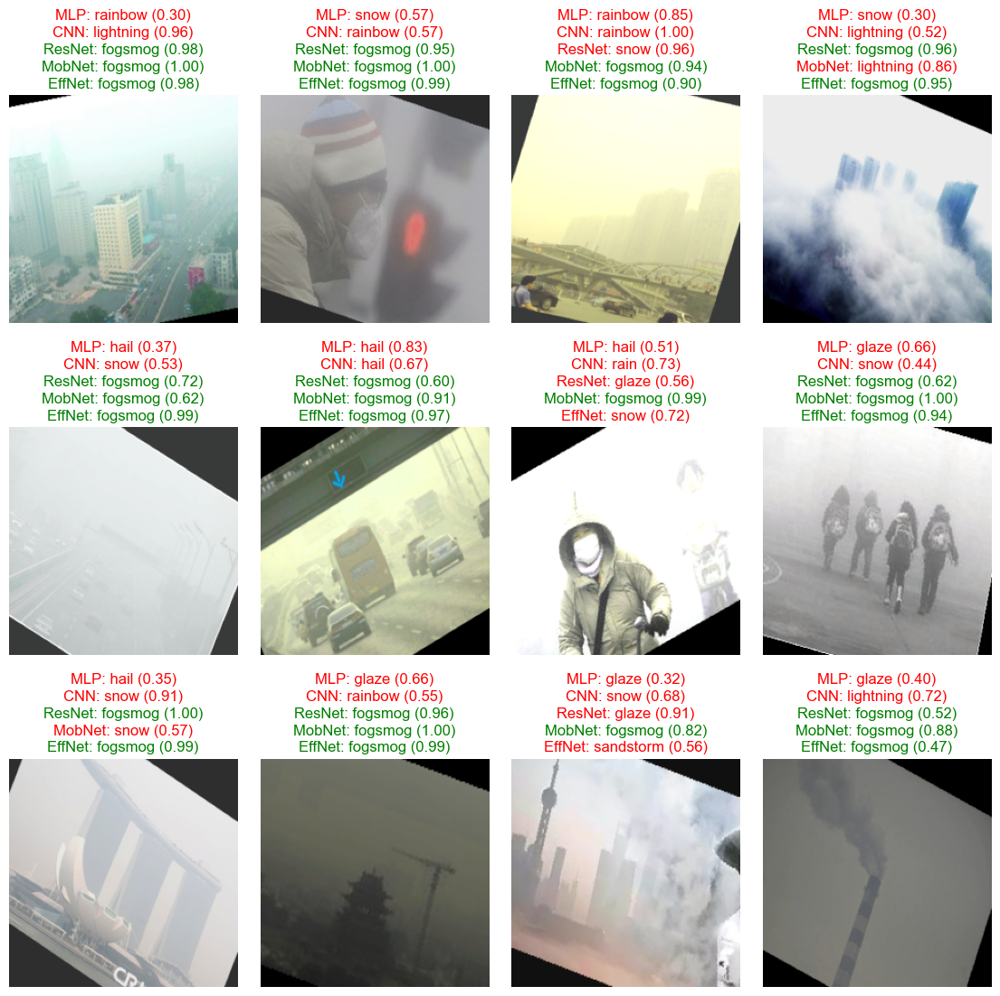

In [23]:
plot_preds("fogsmog", dataset=aug_dataset, indices_dict=aug_indices, all_preds=aug_preds)

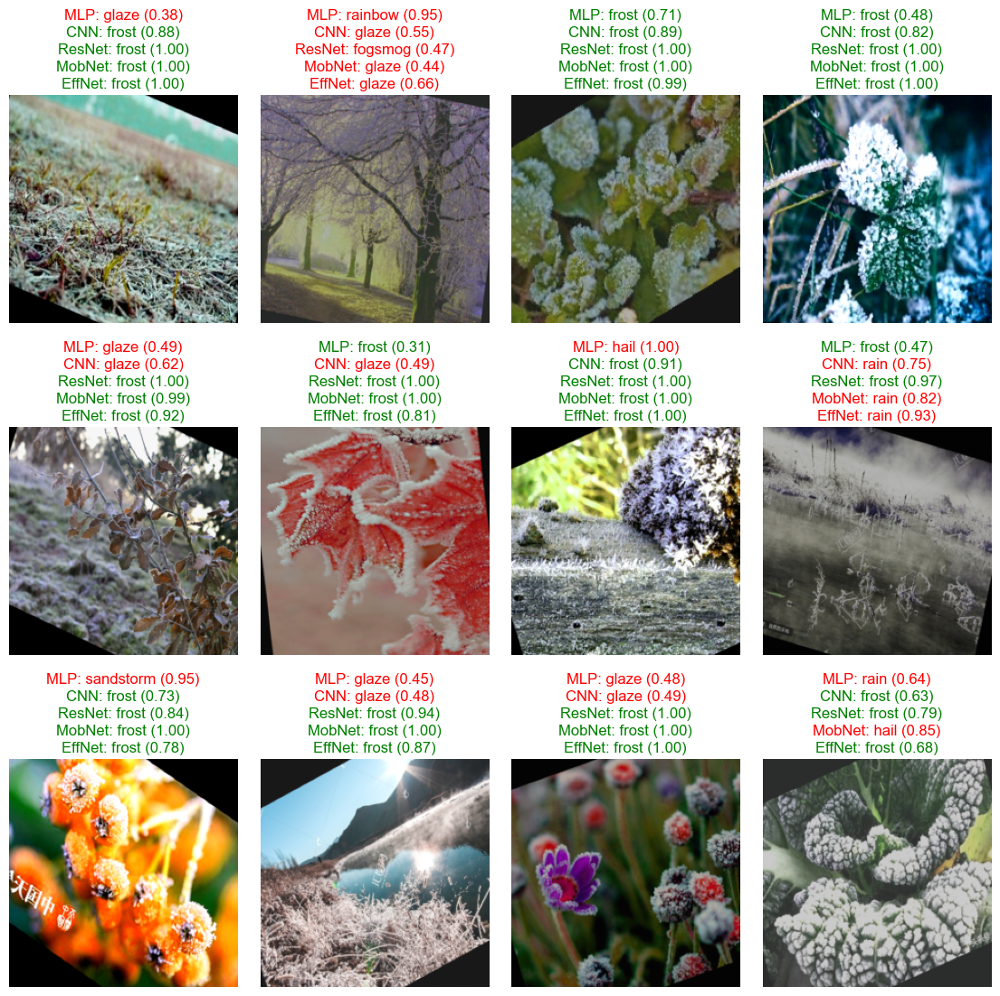

In [24]:
plot_preds("frost", dataset=aug_dataset, indices_dict=aug_indices, all_preds=aug_preds)

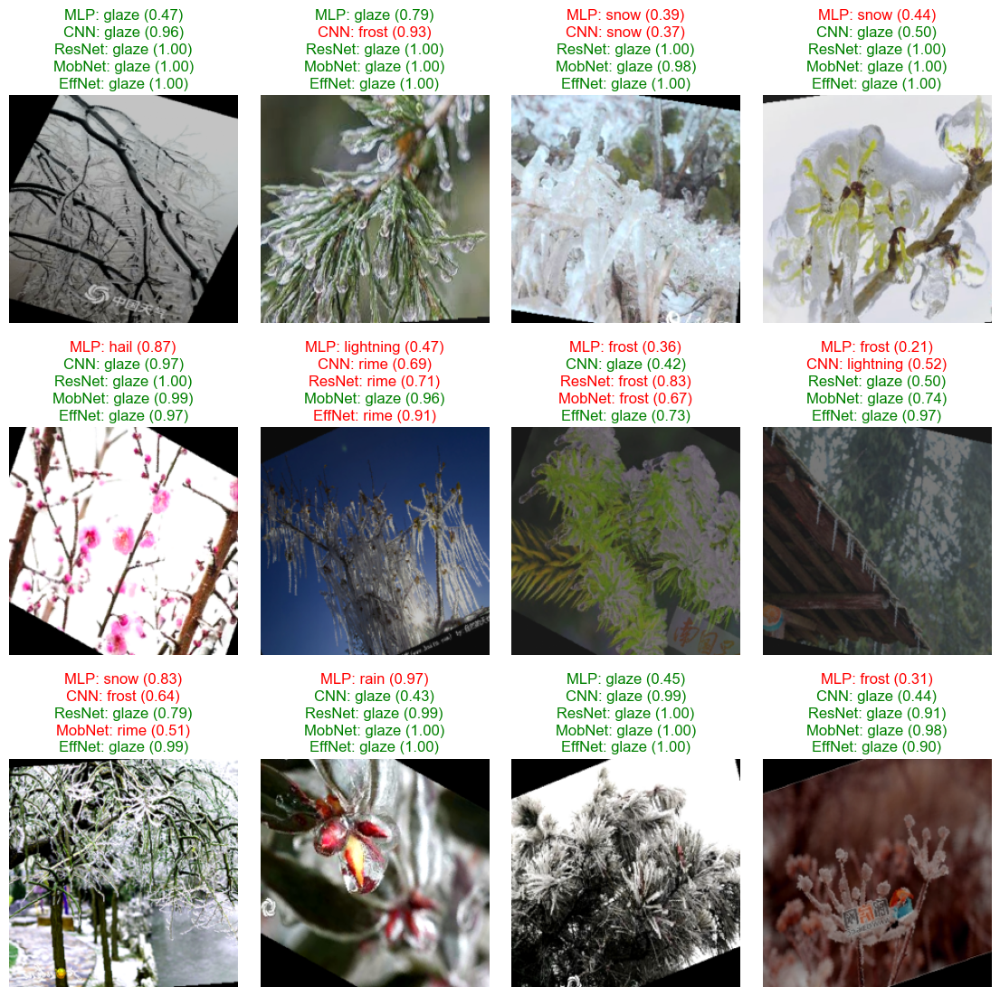

In [25]:
plot_preds("glaze", dataset=aug_dataset, indices_dict=aug_indices, all_preds=aug_preds)

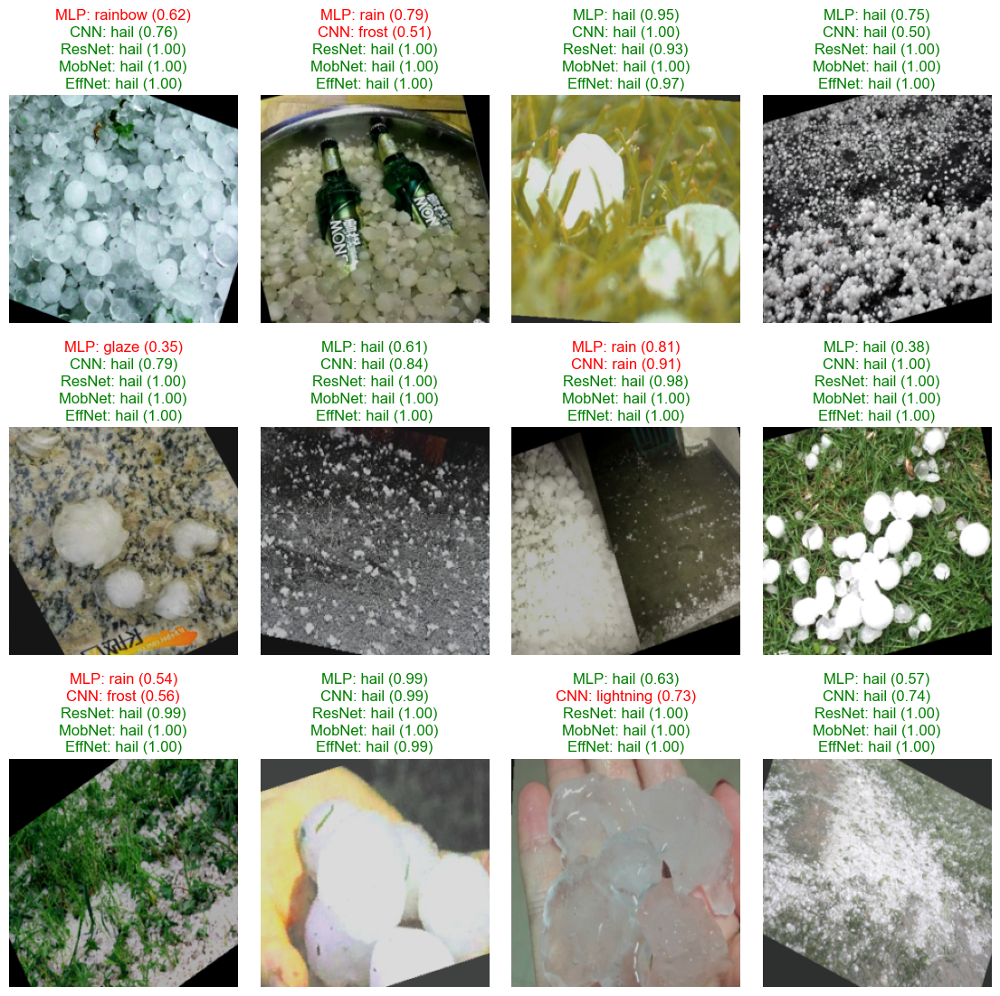

In [26]:
plot_preds("hail", dataset=aug_dataset, indices_dict=aug_indices, all_preds=aug_preds)

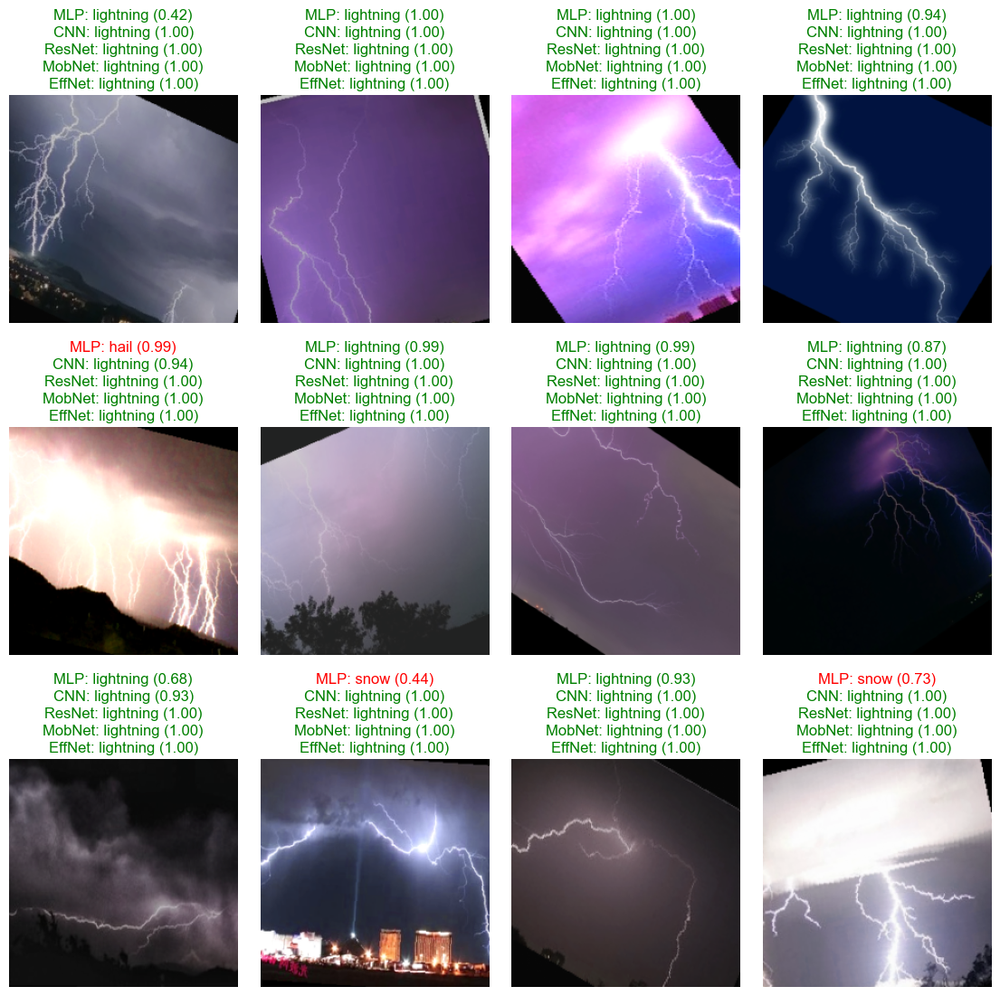

In [27]:
plot_preds("lightning", dataset=aug_dataset, indices_dict=aug_indices, all_preds=aug_preds)

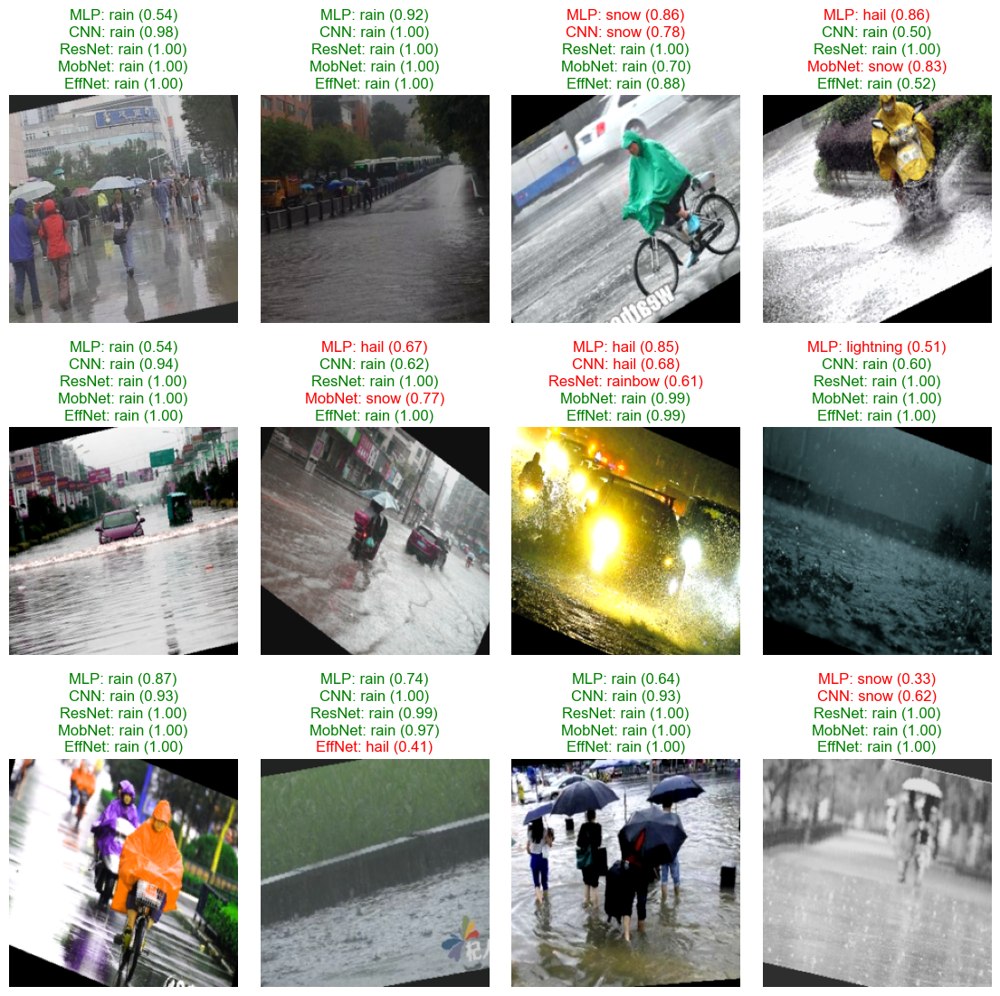

In [28]:
plot_preds("rain", dataset=aug_dataset, indices_dict=aug_indices, all_preds=aug_preds)

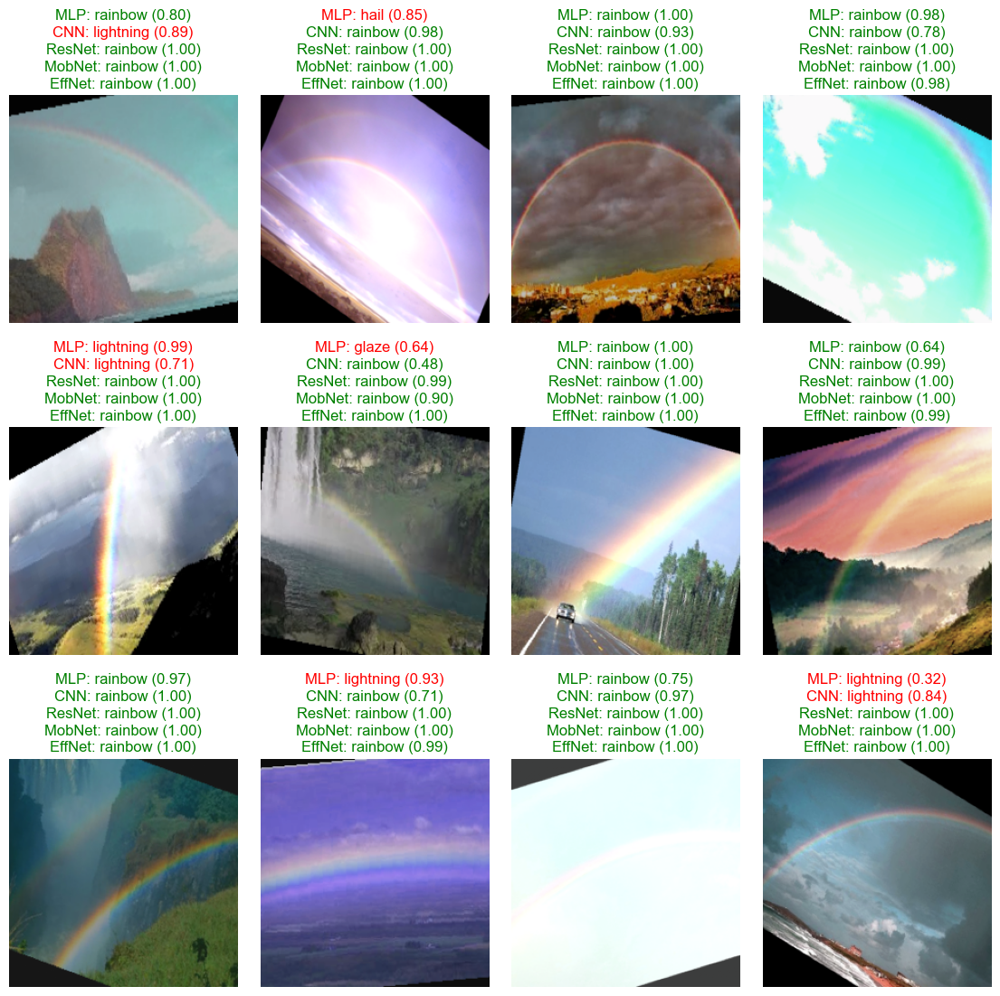

In [29]:
plot_preds("rainbow", dataset=aug_dataset, indices_dict=aug_indices, all_preds=aug_preds)

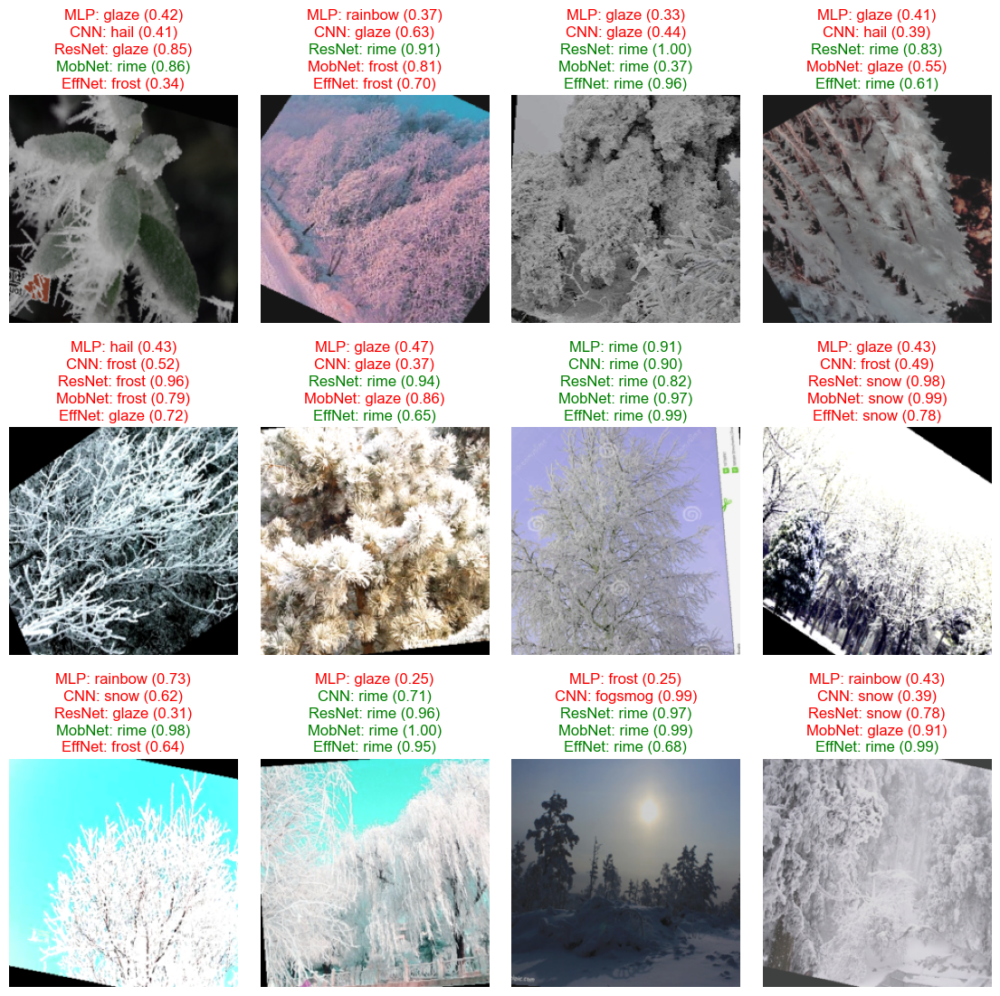

In [30]:
plot_preds("rime", dataset=aug_dataset, indices_dict=aug_indices, all_preds=aug_preds)

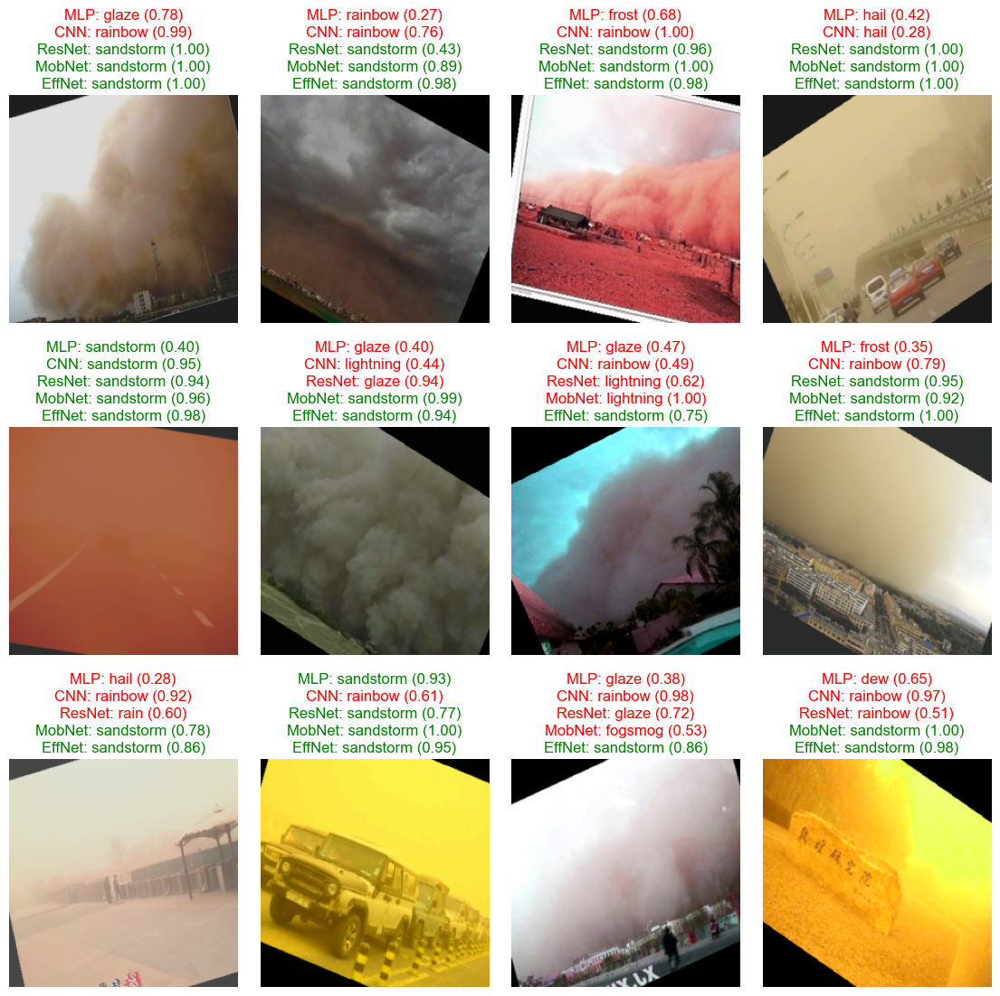

In [31]:
plot_preds("sandstorm", dataset=aug_dataset, indices_dict=aug_indices, all_preds=aug_preds)

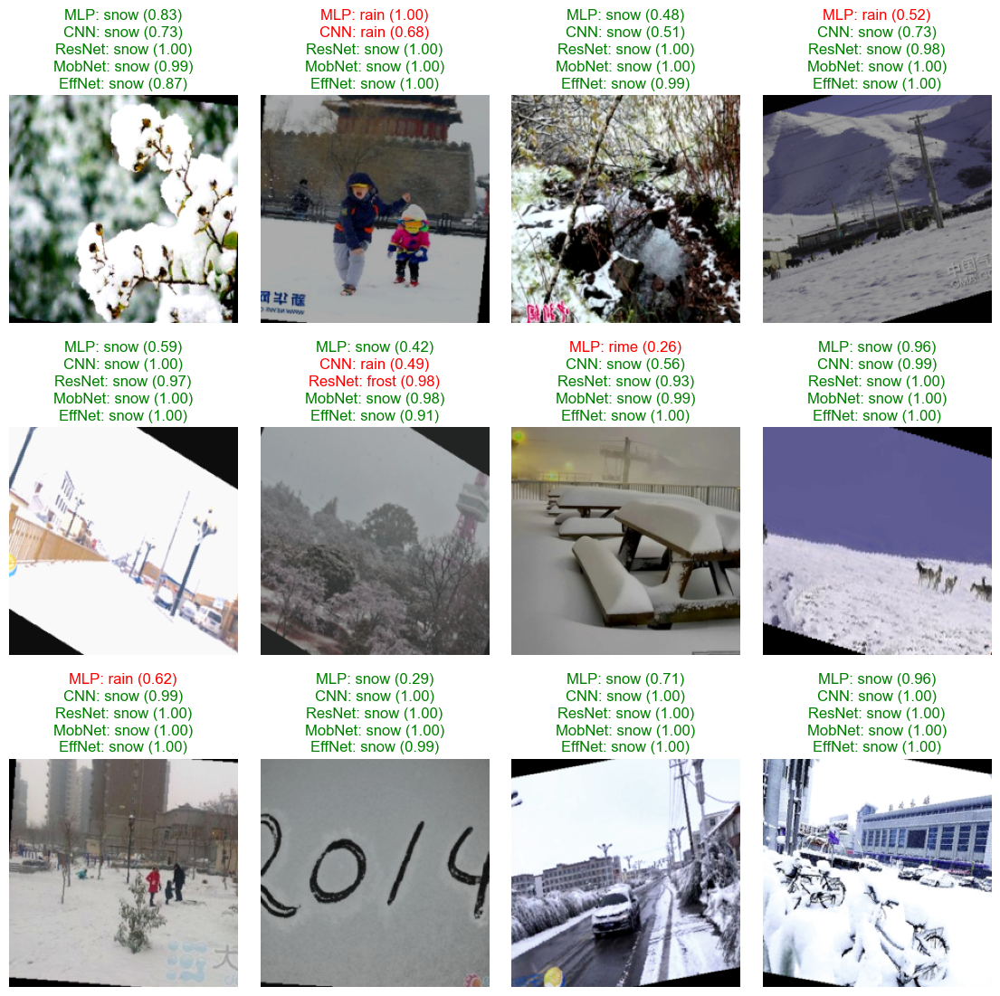

In [32]:
plot_preds("snow", dataset=aug_dataset, indices_dict=aug_indices, all_preds=aug_preds)